# Compare, tune and export

Upload train_candidates.csv and student_test_candidates.csv to the Colab Files panel. The student-test filename with (1) is also accepted. Put the five metrics CSVs and five .joblib files from notebooks 01–05 in pathsnap_real/.

The winner has the highest training CV macro F1. Student-test metrics are shown for comparison. To run the required Bayesian tuning, keep RUN_BAYESIAN_TUNING enabled. The notebook exports candidate_scores.csv for Person 3 and selected_pipeline.joblib for Person 4.

In [3]:
from pathlib import Path

root = Path("/content")
folder = root / "pathsnap_real"
folder.mkdir(exist_ok=True)

for name in [
    "01_logistic_regression.csv",
    "02_gaussian_nb.csv",
    "03_decision_tree.csv",
    "04_random_forest.csv",
    "05_hist_gradient_boosting.csv",
]:
    source = root / name
    if source.exists():
        source.replace(folder / name)
    print(f"{'Ready' if (folder / name).exists() else 'Missing'}: {name}")

Ready: 01_logistic_regression.csv
Ready: 02_gaussian_nb.csv
Ready: 03_decision_tree.csv
Ready: 04_random_forest.csv
Ready: 05_hist_gradient_boosting.csv


In [1]:
from pathlib import Path
from shutil import copy2

folder = Path("/content/pathsnap_real")
folder.mkdir(exist_ok=True)

for path in sorted(Path("/").glob("0[1-5]_*.csv")):
    copy2(path, folder / path.name)
    print("Copied:", path.name)

In [4]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import f1_score, log_loss
from time import perf_counter

FEATURES = ['dist_m', 'dist_min_m', 'dist_rel_m', 'rank_dist', 'n_cands', 'proj_frac', 'arc_len_m', 'dist_end_m', 'head_diff_deg', 'head_cos', 'speed_mps', 'moving', 'dt_prev_s', 'dist_prev_pt_m', 'dist_next_pt_m', 'has_reverse', 'deg_from', 'deg_to']
KEYS = ["trip_id", "observation_index", "arc_id"]
ROOT = Path("pathsnap_real")
ROOT.mkdir(exist_ok=True)

def load_candidates(filename):
    if not Path(filename).exists():
        raise FileNotFoundError(f"Upload {filename} to the Colab Files panel.")
    frame = pd.read_csv(filename, dtype={"trip_id": str})
    missing = set(KEYS + FEATURES + ["label"]) - set(frame.columns)
    if missing:
        raise ValueError(f"{filename} is missing columns: {sorted(missing)}")
    assert not frame[KEYS].isna().any().any(), f"Missing IDs in {filename}"
    assert not frame.duplicated(KEYS).any(), f"Duplicate candidate IDs in {filename}"
    assert frame["label"].isin([0, 1]).all(), f"Bad labels in {filename}"
    return frame

train = load_candidates("train_candidates.csv")
test_path = Path("student_test_candidates.csv")
if not test_path.exists():
    test_path = Path("student_test_candidates(1).csv")
test = load_candidates(test_path)

assert set(train.trip_id).isdisjoint(test.trip_id)
assert train.trip_id.nunique() >= 2
X, y = train[FEATURES], train.label
folds = list(GroupKFold(min(5, train.trip_id.nunique())).split(X, y, train.trip_id))
assert all(y.iloc[i].nunique() == 2 for i, _ in folds)

def evaluate(model):
    start = perf_counter()
    probabilities = model.predict_proba(test[FEATURES])
    seconds = perf_counter() - start
    scored = test[KEYS + ["label"]].copy()
    scored["p_match"] = probabilities[:, list(model.classes_).index(1)]
    top = scored.sort_values("p_match", ascending=False, kind="stable").drop_duplicates(KEYS[:2])
    return scored, {
        "student_top1_with_candidates": top.label.mean(),
        "student_candidate_macro_f1": f1_score(test.label, model.classes_[probabilities.argmax(axis=1)], average="macro"),
        "log_loss": log_loss(test.label, probabilities, labels=model.classes_),
        "inference_seconds": seconds,
    }


In [5]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

NAMES = ['01_logistic_regression', '02_gaussian_nb', '03_decision_tree', '04_random_forest', '05_hist_gradient_boosting']
comparison = pd.concat([pd.read_csv(ROOT / f"{name}.csv") for name in NAMES], ignore_index=True)
comparison = comparison.sort_values(["cv_macro_f1", "model"], ascending=[False, True])
display(comparison)
comparison.to_csv(ROOT / "model_comparison.csv", index=False)

winner = comparison.iloc[0].model
print("Selected:", winner)

# Constructing the pipeline/model from scratch as we do not have the pre-trained joblib file
if winner == '01_logistic_regression':
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
elif winner == '02_gaussian_nb':
    model = make_pipeline(StandardScaler(), GaussianNB())
elif winner == '03_decision_tree':
    model = make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=42))
elif winner == '04_random_forest':
    model = make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42))
elif winner == '05_hist_gradient_boosting':
    model = make_pipeline(StandardScaler(), HistGradientBoostingClassifier(random_state=42))

# Fit the model on training data
print(f"Fitting {winner} on the training data...")
model.fit(X, y)

,model,cv_macro_f1,student_top1_with_candidates,student_candidate_macro_f1,log_loss,inference_seconds
4,05_hist_gradient_boosting,0.923231,0.872443,0.927751,0.055019,1.972549
3,04_random_forest,0.920887,0.867745,0.924161,0.055041,0.525569
2,03_decision_tree,0.916965,0.870929,0.925987,0.087735,0.082231
0,01_logistic_regression,0.901018,0.856994,0.907144,0.075843,0.166827
1,02_gaussian_nb,0.825294,0.825418,0.817809,0.542196,0.089673


Selected: 05_hist_gradient_boosting
Fitting 05_hist_gradient_boosting on the training data...


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('histgradientboostingclassifier',
                 HistGradientBoostingClassifier(random_state=42))])

In [12]:
RUN_BAYESIAN_TUNING = True
final_model = model
if RUN_BAYESIAN_TUNING:
    from importlib.util import find_spec
    import subprocess
    import sys

    if find_spec("optuna") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "optuna"])
    import optuna
    from sklearn.base import clone

    step, estimator = model.steps[-1]
    def objective(trial):
        if winner == "01_logistic_regression":
            params = {"C": trial.suggest_float("C", 0.001, 100, log=True)}
        elif winner == "02_gaussian_nb":
            params = {"var_smoothing": trial.suggest_float("var_smoothing", 1e-12, 1e-2, log=True)}
        elif winner in ("03_decision_tree", "04_random_forest"):
            params = {"max_depth": trial.suggest_int("max_depth", 4, 22),
                      "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20)}
        else:
            params = {"learning_rate": trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
                      "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 10, 63)}
        trial_model = clone(model).set_params(**{f"{step}__{k}": v for k, v in params.items()})
        return cross_val_score(trial_model, X, y, cv=folds, scoring="f1_macro", error_score="raise").mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=5))
    start = perf_counter()
    study.optimize(objective, n_trials=15)
    print(f"Search seconds: {perf_counter() - start:.1f}")
    study.trials_dataframe().to_csv(ROOT / "bayesian_trials.csv", index=False)
    final_model = clone(model).set_params(**{f"{step}__{k}": v for k, v in study.best_params.items()})
    final_model.fit(X, y)
    _, tuned_metrics = evaluate(final_model)
    display(pd.DataFrame([{"variant": "untuned", **evaluate(model)[1]},
                          {"variant": "tuned", **tuned_metrics}]))
    print("Best parameters:", study.best_params, "| CV macro F1:", study.best_value)

scored, _ = evaluate(final_model)
scored[KEYS + ["p_match"]].to_csv(ROOT / "candidate_scores.csv", index=False)
joblib.dump(final_model, ROOT / "selected_pipeline.joblib")
print(ROOT / "candidate_scores.csv", ROOT / "selected_pipeline.joblib")

[I 2026-11-18 08:59:52,919] A new study created in memory with name: no-name-1efd970b-c7d6-439f-b613-c13eda308e3a
[I 2026-11-18 09:03:35,374] Trial 0 finished with value: 0.9247140340208885 and parameters: {'learning_rate': 0.05514718587869894, 'max_leaf_nodes': 61}. Best is trial 0 with value: 0.9247140340208885.
[I 2026-11-18 09:05:27,371] Trial 1 finished with value: 0.922491074150042 and parameters: {'learning_rate': 0.14518497439122724, 'max_leaf_nodes': 42}. Best is trial 0 with value: 0.9247140340208885.
[W 2026-11-18 09:07:37,386] Trial 2 failed with parameters: {'learning_rate': 0.030515616964102342, 'max_leaf_nodes': 18} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/optuna/study/_optimize.py", line 210, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_1450/3565251132.py", line 26, in objective
    return cross_val_score(trial_model, X, y, cv=folds, scoring="f1_macro

KeyboardInterrupt: 

In [13]:
from sklearn.base import clone

step = model.steps[-1][0]
best_params = study.best_params
review_model = clone(model).set_params(
    **{f"{step}__{name}": value for name, value in best_params.items()}
)

print("Fitting the best completed trial:", best_params, flush=True)
review_model.fit(X, y)

scored, metrics = evaluate(review_model)
print(f"Student-test Top-1: {metrics['student_top1_with_candidates']:.2%}")

scored[KEYS + ["p_match"]].to_csv(ROOT / "candidate_scores.csv", index=False)
joblib.dump(review_model, ROOT / "selected_pipeline.joblib")
study.trials_dataframe().to_csv(ROOT / "bayesian_trials.csv", index=False)
print("Saved candidate scores, model, and trial history to", ROOT)

Fitting the best completed trial: {'learning_rate': 0.05514718587869894, 'max_leaf_nodes': 61}
Student-test Top-1: 87.28%
Saved candidate scores, model, and trial history to pathsnap_real


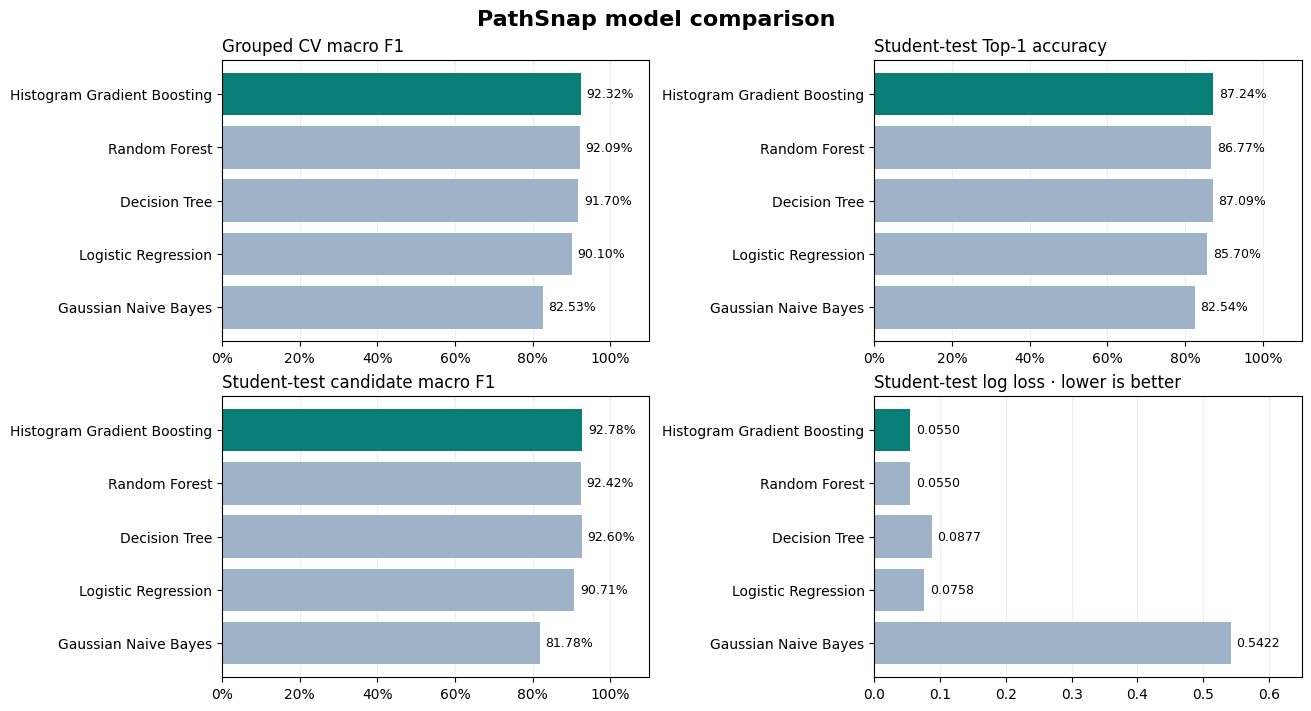

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

labels = {
    "01_logistic_regression": "Logistic Regression",
    "02_gaussian_nb": "Gaussian Naive Bayes",
    "03_decision_tree": "Decision Tree",
    "04_random_forest": "Random Forest",
    "05_hist_gradient_boosting": "Histogram Gradient Boosting",
}
panels = [
    ("cv_macro_f1", "Grouped CV macro F1", True),
    ("student_top1_with_candidates", "Student-test Top-1 accuracy", True),
    ("student_candidate_macro_f1", "Student-test candidate macro F1", True),
    ("log_loss", "Student-test log loss · lower is better", False),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
fig.suptitle("PathSnap model comparison", fontsize=16, fontweight="bold")
for ax, (column, title, percent) in zip(axes.flat, panels):
    values = comparison[column]
    names = comparison["model"].map(labels)
    best = values.max() if percent else values.min()
    colors = ["#087f76" if value == best else "#9eb2c8" for value in values]
    bars = ax.barh(names, values, color=colors)
    annotations = [f"{value:.2%}" if percent else f"{value:.4f}" for value in values]
    ax.bar_label(bars, labels=annotations, padding=4, fontsize=9)
    ax.set_title(title, loc="left")
    ax.invert_yaxis()
    ax.set_xlim(0, 1.10 if percent else best + 1.18 * (values.max() - best) + 0.02)
    if percent:
        ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.savefig(ROOT / "model_comparison_plots.png", dpi=220, bbox_inches="tight")
plt.show()


In [11]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import f1_score, log_loss
from time import perf_counter
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES = ['dist_m', 'dist_min_m', 'dist_rel_m', 'rank_dist', 'n_cands', 'proj_frac', 'arc_len_m', 'dist_end_m', 'head_diff_deg', 'head_cos', 'speed_mps', 'moving', 'dt_prev_s', 'dist_prev_pt_m', 'dist_next_pt_m', 'has_reverse', 'deg_from', 'deg_to']
KEYS = ["trip_id", "observation_index", "arc_id"]

def load_candidates(filename):
    if not Path(filename).exists():
        raise FileNotFoundError(f"Upload {filename} to the Colab Files panel.")
    frame = pd.read_csv(filename, dtype={"trip_id": str})
    missing = set(KEYS + FEATURES + ["label"]) - set(frame.columns)
    if missing:
        raise ValueError(f"{filename} is missing columns: {sorted(missing)}")
    assert not frame[KEYS].isna().any().any(), f"Missing IDs in {filename}"
    assert not frame.duplicated(KEYS).any(), f"Duplicate candidate IDs in {filename}"
    assert frame["label"].isin([0, 1]).all(), f"Bad labels in {filename}"
    return frame

train = load_candidates("train_candidates.csv")
test_path = Path("student_test_candidates.csv")
if not test_path.exists():
    test_path = Path("student_test_candidates(1).csv")
test = load_candidates(test_path)

assert set(train.trip_id).isdisjoint(test.trip_id)
assert train.trip_id.nunique() >= 2
X, y = train[FEATURES], train.label
folds = list(GroupKFold(min(5, train.trip_id.nunique())).split(X, y, train.trip_id))
assert all(y.iloc[i].nunique() == 2 for i, _ in folds)

def evaluate(model):
    start = perf_counter()
    probabilities = model.predict_proba(test[FEATURES])
    seconds = perf_counter() - start
    scored = test[KEYS + ["label"]].copy()
    scored["p_match"] = probabilities[:, list(model.classes_).index(1)]
    top = scored.sort_values("p_match", ascending=False, kind="stable").drop_duplicates(KEYS[:2])
    return scored, {
        "student_top1_with_candidates": top.label.mean(),
        "student_candidate_macro_f1": f1_score(test.label, model.classes_[probabilities.argmax(axis=1)], average="macro"),
        "log_loss": log_loss(test.label, probabilities, labels=model.classes_),
        "inference_seconds": seconds,
    }